# Calibración, robustez, equidad y explicabilidad del clasificador de texto

Un clasificador de currículos que se usa para ordenar candidatos necesita más que una F1 alta. Sus probabilidades deben significar lo que dicen, no debe depender de atajos como el título o la palabra de la categoría, no debe cambiar su decisión por el género gramatical del texto, y sus explicaciones deben señalar las palabras que de verdad mueven la predicción. Este capítulo mide cada una de esas propiedades en test. Los resultados los generan `python scripts/analysis.py nlp` y los trabajos `nlp_explain` y `nlp_efficiency` de la cola.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from project.book_utils import CAT, MUTED, ci, exists, need, pct, style

style()
pd.set_option("display.precision", 3)
S = need("analysis/nlp_stats/stats.pkl")
L = S["labels"]
ORDER = [m for m in ["tfidf_lr", "nbsvm", "tfidf_xgb", "fasttext", "cnn1d", "bilstm", "distilbert"] if m in S["models"]]
COL = {m: CAT[i % len(CAT)] for i, m in enumerate(ORDER)}

## Calibración y escalado de temperatura

El escalado de temperatura divide los *logits* por un escalar T ajustado en validación minimizando la log-verosimilitud negativa {cite:p}`guo2017calibration`. Como divide todos los *logits* por el mismo número, no cambia el orden de las clases ni, por tanto, la exactitud (capítulo {doc}`04_fundamentos_teoricos`, punto 5). Para los modelos que no producen *logits* (TF-IDF + RL, NB-SVM, XGBoost, FastText) aplicamos la misma operación sobre el logaritmo de las probabilidades, que es equivalente salvo una constante por documento.

In [2]:
C = S["calibration"]
ct = C["table"].groupby("model")[["T", "ece", "ece_ts", "nll", "nll_ts", "brier", "brier_ts", "aurc"]].mean().reindex(ORDER)
ct.index = ct.index.map(L)
display(ct.rename(columns={"ece": "ECE", "ece_ts": "ECE tras TS", "nll": "NLL", "nll_ts": "NLL tras TS", "brier": "Brier",
                           "brier_ts": "Brier tras TS", "aurc": "AURC"}))
same_acc = bool((C["table"].acc == C["table"].acc_ts).all())
display(Markdown("La exactitud es idéntica antes y después del escalado en todos los modelos y semillas, como predice la teoría."
                 if same_acc else "En alguna semilla la exactitud cambia tras el escalado por empates en el *argmax*; revisamos ese caso aparte."))

,T,ECE,ECE tras TS,NLL,NLL tras TS,Brier,Brier tras TS,AURC
model,,,,,,,,
TF-IDF + RL,0.844,0.069,0.067,1.070,1.067,0.410,0.408,0.100
NB-SVM,0.986,0.057,0.066,0.912,0.912,0.352,0.352,0.078
TF-IDF + XGBoost,1.082,0.064,0.070,0.924,0.916,0.355,0.356,0.093
FastText,1.030,0.081,0.086,1.861,1.858,0.650,0.652,0.283
CNN-1D,1.111,0.043,0.047,0.688,0.679,0.257,0.256,0.037
BiLSTM,0.958,0.075,0.065,0.894,0.889,0.320,0.318,0.050
DistilBERT,0.867,0.088,0.070,0.674,0.645,0.231,0.229,0.028


La exactitud es idéntica antes y después del escalado en todos los modelos y semillas, como predice la teoría.

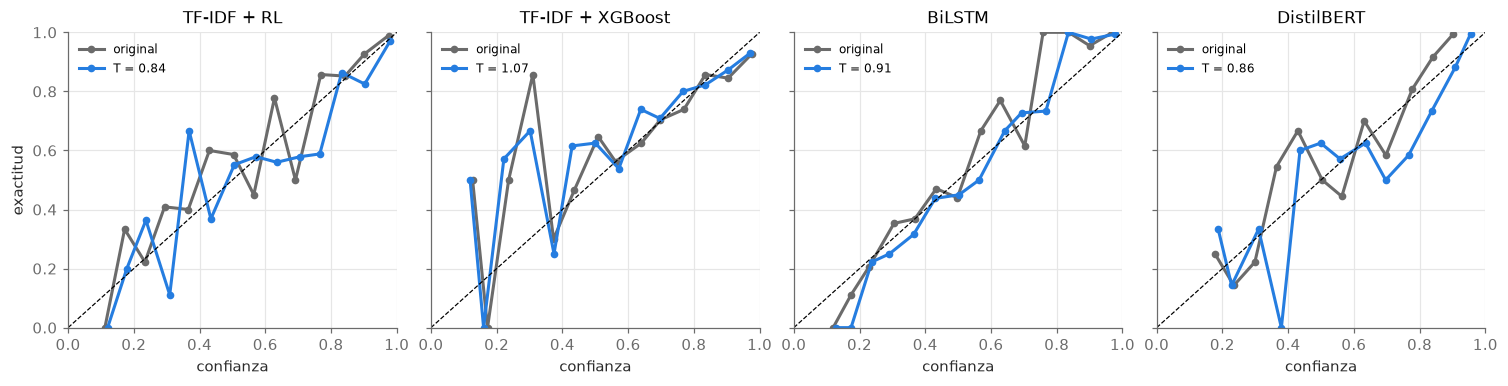

In [3]:
rel = C["reliability"]
show = [m for m in ("tfidf_lr", "tfidf_xgb", "bilstm", "distilbert") if m in rel]
fig, axes = plt.subplots(1, len(show), figsize=(3.4 * len(show), 3.4), sharey=True)
for ax, m in zip(np.atleast_1d(axes), show):
    for key, col, lab in (("before", MUTED, "original"), ("after", CAT[0], f"T = {rel[m]['T']:.2f}")):
        b = rel[m][key]
        ok = np.array(b["count"]) > 0
        ax.plot(np.array(b["conf"])[ok], np.array(b["acc"])[ok], "o-", ms=4, color=col, label=lab)
    ax.plot([0, 1], [0, 1], ls="--", color="black", lw=0.8)
    ax.set(title=L[m], xlabel="confianza", xlim=(0, 1), ylim=(0, 1)); ax.legend(fontsize=8, loc="upper left")
np.atleast_1d(axes)[0].set_ylabel("exactitud")
plt.show()

Un punto bajo la diagonal es sobreconfianza (el modelo dice 0.9 y acierta menos del 90 % de las veces), y uno sobre ella, subconfianza. T > 1 corrige sobreconfianza aplanando la distribución y T < 1 corrige subconfianza.

### H5: calibración de DistilBERT

In [4]:
h5 = C["h5"]
if h5:
    display(Markdown(
        f"ECE de DistilBERT en test: {h5['ece_bert']:.3f} ± {h5['ece_bert_sd']:.3f} ({int(S["results"].n_seeds.get("distilbert", 0))} semillas), frente a {h5['ece_lr']:.3f} de TF-IDF + RL. "
        f"Tras el escalado (T medio = {h5['T']:.2f}) baja a {h5['ece_bert_ts']:.3f}; la reducción en la semilla 0 es "
        f"{ci(h5['reduction'], h5['red_lo'], h5['red_hi'])}. **H5 {'se refuta' if h5['refuted'] else 'no se refuta'}**: "
        + ("se cumplen las tres condiciones pre-registradas (ECE > 0.05, mayor que la de TF-IDF + RL y reducción con IC por encima de 0)."
           if not h5["refuted"] else "de las tres condiciones pre-registradas no se cumple " + "; ni ".join(c for c, ok in (
               (f"«ECE > 0.05» ({h5['ece_bert']:.3f})", h5["ece_bert"] > 0.05),
               (f"«ECE mayor que la de TF-IDF + RL» ({h5['ece_bert']:.3f} frente a {h5['ece_lr']:.3f})", h5["ece_bert"] > h5["ece_lr"]),
               (f"«reducción con IC por encima de 0» (límite inferior {h5['red_lo']:.3f})", h5["red_lo"] > 0)) if not ok) + ".")))
    if abs(h5["red_lo"]) < 0.0005:
        display(Markdown(f"El límite inferior del IC de la reducción es {h5['red_lo']:.5f}: la tercera condición se cumple por un margen "
                         "que el redondeo a tres decimales oculta, y otra semilla o otro remuestreo podrían invertirla."))
    display(Markdown(
        f"La temperatura media T = {h5['T']:.2f} es "
        + ("menor que 1: el escalado *afila* la distribución, es decir, DistilBERT está **subconfiado** (asigna a la clase elegida "
           "menos probabilidad de la que justifica su tasa de aciertos). Es la dirección contraria a la sobreconfianza que "
           "{cite:t}`guo2017calibration` describen en redes profundas; la ECE no distingue la dirección, el diagrama de fiabilidad sí."
           if h5["T"] < 1 else
           "mayor que 1: el escalado aplana la distribución, es decir, DistilBERT está **sobreconfiado**, la dirección que "
           "{cite:t}`guo2017calibration` describen en redes profundas.")))
else:
    display(Markdown("DistilBERT no terminó; H5 queda sin contrastar."))

ECE de DistilBERT en test: 0.088 ± 0.009 (5 semillas), frente a 0.069 de TF-IDF + RL. Tras el escalado (T medio = 0.87) baja a 0.070; la reducción en la semilla 0 es 0.032 [0.000, 0.057]. **H5 no se refuta**: se cumplen las tres condiciones pre-registradas (ECE > 0.05, mayor que la de TF-IDF + RL y reducción con IC por encima de 0).

El límite inferior del IC de la reducción es 0.00010: la tercera condición se cumple por un margen que el redondeo a tres decimales oculta, y otra semilla o otro remuestreo podrían invertirla.

La temperatura media T = 0.87 es menor que 1: el escalado *afila* la distribución, es decir, DistilBERT está **subconfiado** (asigna a la clase elegida menos probabilidad de la que justifica su tasa de aciertos). Es la dirección contraria a la sobreconfianza que {cite:t}`guo2017calibration` describen en redes profundas; la ECE no distingue la dirección, el diagrama de fiabilidad sí.

## Conjuntos de predicción conformes

Con predicción conforme por puntuación de no conformidad LAC {cite:p}`angelopoulos2021conformal` calibrada en validación, cada documento recibe un conjunto de clases que contiene la verdadera con probabilidad ≥ 1 − α, bajo intercambiabilidad entre validación y test. El tamaño medio del conjunto mide cuánta incertidumbre real tiene el modelo: un conjunto de una sola clase es una decisión automática y uno de varias clases es una lista corta para un revisor.

In [5]:
cf = C["conformal"].copy()
cf["modelo"] = cf.model.map(L)
display(cf.pivot_table(index="modelo", columns="alpha", values=["coverage", "mean_size", "singleton"]).rename(
    columns={"coverage": "cobertura", "mean_size": "tamaño medio", "singleton": "fracción de un elemento"}))

cobertura               tamaño medio                \
alpha                 0.05   0.10   0.20         0.05   0.10   0.20   
modelo                                                                
BiLSTM               0.973  0.882  0.804        5.381  2.244  1.282   
CNN-1D               0.957  0.909  0.812        2.834  1.638  0.941   
DistilBERT           0.971  0.930  0.780        4.035  1.689  0.834   
FastText             0.925  0.879  0.783       10.295  7.201  3.914   
NB-SVM               0.936  0.893  0.815        4.027  2.024  1.206   
TF-IDF + RL          0.954  0.903  0.796        6.174  2.646  1.432   
TF-IDF + XGBoost     0.933  0.885  0.820        3.300  2.029  1.268   

                 fracción de un elemento                
alpha                               0.05   0.10   0.20  
modelo                                                  
BiLSTM                             0.273  0.544  0.764  
CNN-1D                             0.448  0.625  0.925  
DistilBERT                         0.542  0.772  0.834  
FastText                           0.011  0.029  0.080  
NB-SVM                             0.442  0.568  0.791  
TF-IDF + RL                        0.241  0.378  0.654  
TF-IDF + XGBoost                   0.287  0.442  0.732

In [6]:
_n = int(S["results"].n_test.max()) if "n_test" in S["results"] else 373
cf["ee"] = np.sqrt(cf.alpha * (1 - cf.alpha) / _n)
cf["desvío"] = cf.coverage - (1 - cf.alpha)
_far = cf[cf["desvío"].abs() > 2 * cf.ee]
_empty = cf[cf.mean_size < 1]
display(Markdown(
    f"La cobertura empírica en test debe quedar cerca de 1 − α. Con {_n} documentos, el error estándar de la cobertura es "
    f"{cf.ee.min():.3f} a {cf.ee.max():.3f} según α. "
    + ("Todas las coberturas quedan a menos de dos errores estándar de 1 − α, compatibles con la garantía."
       if _far.empty else
       "Quedan a más de dos errores estándar de 1 − α: " + "; ".join(
           f"{r.modelo} con α = {r.alpha:.2f} ({r.coverage:.3f}, {r['desvío'] / r.ee:+.1f} EE)" for _, r in _far.iterrows())
       + ". Una cobertura por debajo de 1 − α en test indica que validación y test no son del todo intercambiables para ese modelo.")
    + (" Un tamaño medio menor que 1 significa que algunos documentos reciben un conjunto vacío: LAC no garantiza un conjunto no "
       "vacío, y un conjunto vacío equivale a «ninguna clase alcanza el umbral», que en producción debe ir a revisión humana."
       if len(_empty) else "")))

La cobertura empírica en test debe quedar cerca de 1 − α. Con 373 documentos, el error estándar de la cobertura es 0.011 a 0.021 según α. Quedan a más de dos errores estándar de 1 − α: FastText con α = 0.05 (0.925, -2.2 EE); BiLSTM con α = 0.05 (0.973, +2.1 EE). Una cobertura por debajo de 1 − α en test indica que validación y test no son del todo intercambiables para ese modelo. Un tamaño medio menor que 1 significa que algunos documentos reciben un conjunto vacío: LAC no garantiza un conjunto no vacío, y un conjunto vacío equivale a «ninguna clase alcanza el umbral», que en producción debe ir a revisión humana.

## Clasificación selectiva

Si el modelo decide solo cuando su confianza es alta y deriva el resto a una persona, ¿qué fracción de los currículos puede clasificar automáticamente con una exactitud objetivo? La curva riesgo–cobertura ordena los documentos por confianza y mide el error acumulado.

In [7]:
sel = S["selective"].copy()
sel["modelo"] = sel.model.map(L)
display(sel.pivot_table(index="modelo", columns="target_acc", values="coverage").rename(columns=lambda t: f"cobertura con exactitud ≥ {t:.2f}"))
best = S["errors"]["model"]
r = sel[(sel.model == best)].set_index("target_acc").coverage
display(Markdown(f"Con {L[best]}, el modelo puede decidir solo sobre el {pct(r.get(0.9, 0))} de los currículos manteniendo una exactitud ≥ 0.90 "
                 f"en ellos (ordenados por la confianza de la probabilidad media de las semillas); el resto pasa a revisión humana."))

target_acc,cobertura con exactitud ≥ 0.80,cobertura con exactitud ≥ 0.90,cobertura con exactitud ≥ 0.95
modelo,,,
BiLSTM,0.973,0.818,0.753
CNN-1D,1.000,0.895,0.751
DistilBERT,1.000,0.914,0.786
FastText,0.448,0.198,0.064
NB-SVM,0.930,0.625,0.432
TF-IDF + RL,0.812,0.568,0.429
TF-IDF + XGBoost,0.960,0.576,0.271


Con DistilBERT, el modelo puede decidir solo sobre el 91.4 % de los currículos manteniendo una exactitud ≥ 0.90 en ellos (ordenados por la confianza de la probabilidad media de las semillas); el resto pasa a revisión humana.

Las coberturas se miden sobre el mismo test que ordena por confianza, así que son optimistas en unos puntos porcentuales: el umbral de confianza para producción se fija en validación (capítulo {doc}`30_mlops`).

## Robustez a perturbaciones

Aplicamos once perturbaciones a los textos de test, sin reentrenar, en la línea de las pruebas de comportamiento de {cite:p}`ribeiro2020checklist`:

| Perturbación | Qué mide |
|---|---|
| sin título | Dependencia del encabezado: se borra la primera línea, que suele nombrar el cargo |
| sin categoría | Dependencia de la palabra de la etiqueta escrita en el texto (fuga): se borran en todo el documento las palabras del nombre de la categoría y las que comparten su raíz de 5 letras |
| sin título ni categoría | Las dos anteriores a la vez |
| *typos* 5 % / 15 % | Intercambio de dos letras adyacentes en el 5 % o el 15 % de las palabras de 4 o más letras |
| mayúsculas / minúsculas | Sensibilidad a la capitalización |
| género femenino / masculino | Todos los pronombres y términos con género llevados a femenino o a masculino (contrafactual) |
| sin geografía | Países, estados de EE. UU., gentilicios y términos militares borrados (*proxies* de origen nacional o servicio militar) |
| primeras 200 palabras | Longitud y truncamiento |

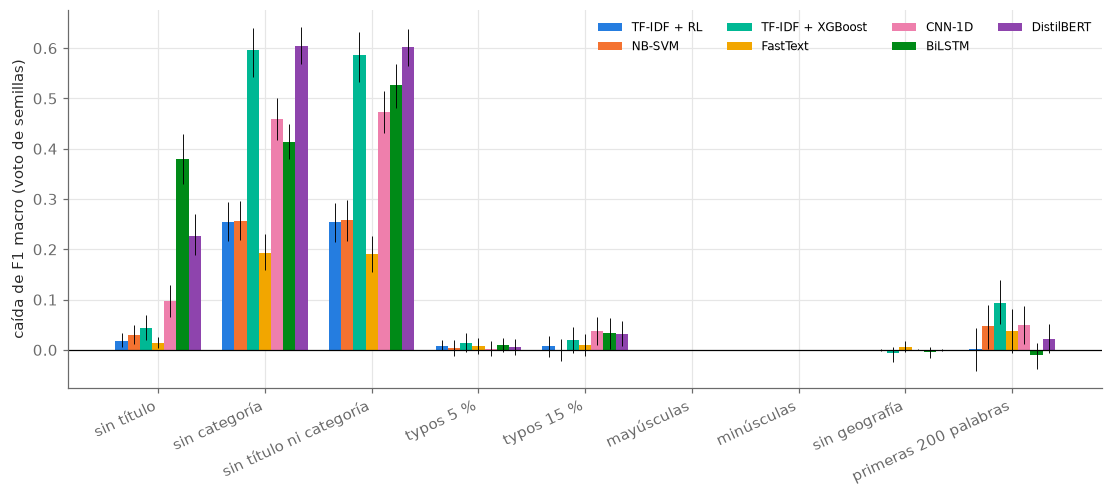

In [8]:
Pt = S["perturbations"].copy()
Pt = Pt[Pt.model.isin(ORDER)]
order_p = ["sin_titulo", "sin_categoria", "sin_titulo_ni_categoria", "typos_5", "typos_15", "mayusculas", "minusculas", "sin_geografia",
           "primeras_200"]
PN = {"sin_titulo": "sin título", "sin_categoria": "sin categoría", "sin_titulo_ni_categoria": "sin título ni categoría",
      "typos_5": "typos 5 %", "typos_15": "typos 15 %", "mayusculas": "mayúsculas", "minusculas": "minúsculas",
      "sin_geografia": "sin geografía", "primeras_200": "primeras 200 palabras"}
fig, ax = plt.subplots(figsize=(10, 4.4))
w = 0.8 / len(ORDER)
for k, m in enumerate(ORDER):
    g = Pt[Pt.model == m].set_index("perturbation").reindex(order_p)
    x = np.arange(len(order_p)) + (k - len(ORDER) / 2 + 0.5) * w
    ax.bar(x, g["drop"], w, color=COL[m], label=L[m])
    ax.errorbar(x, g["drop"], yerr=[g["drop"] - g.drop_lo, g.drop_hi - g["drop"]], fmt="none", ecolor="black", elinewidth=0.6, capsize=0)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(order_p)), [PN.get(p, p) for p in order_p], rotation=25, ha="right")
ax.set(ylabel="caída de F1 macro (voto de semillas)"); ax.legend(fontsize=8, ncol=4)
plt.show()

In [9]:
piv = Pt.pivot_table(index="perturbation", columns="model", values="drop").reindex(order_p)[ORDER]
worst = piv.stack().idxmax()
display(Markdown(f"La caída más grande es la de {L[worst[1]]} con «{PN.get(worst[0], worst[0])}» ({piv.loc[worst]:.3f} de F1 macro). "
                 f"Al quitar título y categoría, la caída va de {piv.loc['sin_titulo_ni_categoria'].min():.3f} a "
                 f"{piv.loc['sin_titulo_ni_categoria'].max():.3f} según el modelo."))

La caída más grande es la de DistilBERT con «sin categoría» (0.604 de F1 macro). Al quitar título y categoría, la caída va de 0.191 a 0.602 según el modelo.

La caída al borrar la palabra de la categoría mide cuánto del desempeño viene de una fuga en los datos: un currículo de «Chef» que dice «chef» en el texto se clasifica bien sin entender el resto del documento. Una caída grande indica que la cifra de la tabla principal sobreestima el desempeño en currículos que no nombran su propia categoría. Las barras de error son IC 95 % *bootstrap* pareado sobre documentos.

## Equidad

El conjunto de datos no tiene un atributo protegido declarado. Usamos el género gramatical del texto como el único indicio disponible, con dos mediciones complementarias.

**Contrafactual.** Cada currículo se reescribe dos veces, con todos los términos de género en femenino y en masculino, y medimos la fracción de documentos cuya predicción cambia. Un modelo que no usa el género tiene una tasa de cambio de 0.

In [10]:
fz = S["fairness"]
cfz = fz["counterfactual"].copy()
cfz = cfz[cfz.model.isin(ORDER)]
cfz["modelo"] = cfz.model.map(L)
display(cfz[["modelo", "flip_rate", "n_flips", "mean_tv", "acc_f", "acc_m"]].rename(columns={
    "flip_rate": "tasa de cambio", "n_flips": "documentos que cambian", "mean_tv": "variación total media",
    "acc_f": "exactitud (femenino)", "acc_m": "exactitud (masculino)"}).style.hide(axis="index").format(precision=3))
_sgn = fz["subgroups"].groupby("group").n.first()
_n_all = 373
_n_none = int(_sgn.get("sin términos de género", 0))
_n_g = _n_all - _n_none
if _n_none:
    _mx = cfz.loc[cfz.n_flips.idxmax()]
    display(Markdown(
        f"El contrafactual solo puede cambiar los currículos que contienen algún término de género: {_n_g} de {_n_all} "
        f"(los {_n_none} restantes quedan idénticos al reescribirlos). Sobre esos {_n_g} documentos, el modelo con más cambios es "
        f"{_mx.modelo}, con {int(_mx.n_flips)} ({100 * _mx.n_flips / max(_n_g, 1):.1f} %). La tasa baja dice que la predicción no "
        "depende de los pronombres y términos de la lista; no mide el género que el modelo pueda inferir por otras vías, como "
        "nombres, aficiones o tipo de institución, que el contrafactual deja intactos."))

modelo,tasa de cambio,documentos que cambian,variación total media,exactitud (femenino),exactitud (masculino)
TF-IDF + RL,0.000,0,0.002,0.713,0.713
NB-SVM,0.003,1,0.003,0.756,0.753
TF-IDF + XGBoost,0.003,1,0.002,0.780,0.780
FastText,0.003,1,0.002,0.560,0.558
CNN-1D,0.000,0,0.001,0.834,0.834
BiLSTM,0.003,1,0.002,0.783,0.783
DistilBERT,0.000,0,0.000,0.847,0.847


El contrafactual solo puede cambiar los currículos que contienen algún término de género: 95 de 373 (los 278 restantes quedan idénticos al reescribirlos). Sobre esos 95 documentos, el modelo con más cambios es NB-SVM, con 1 (1.1 %). La tasa baja dice que la predicción no depende de los pronombres y términos de la lista; no mide el género que el modelo pueda inferir por otras vías, como nombres, aficiones o tipo de institución, que el contrafactual deja intactos.

**Subgrupos observados.** Dividimos test según los términos de género que contiene el texto original y comparamos el desempeño. A diferencia del contrafactual, aquí los grupos difieren también en profesión, así que una diferencia de F1 puede venir de la composición de clases y no del género.

In [11]:
sg = fz["subgroups"].copy()
sg = sg[sg.model.isin(ORDER)]
sg["F1 macro [IC 95 %]"] = [ci(a, b, c) for a, b, c in zip(sg.f1, sg.lo, sg.hi)]
sg["modelo"] = sg.model.map(L)
display(sg.pivot_table(index="modelo", columns="group", values="F1 macro [IC 95 %]", aggfunc="first"))
display(sg.groupby("group").n.first().rename("documentos").to_frame())
_edge = (sg.hi - sg.f1) < (sg.f1 - sg.lo) / 3
if _edge.any():
    display(Markdown(
        "En varios grupos la estimación puntual queda cerca del extremo superior de su IC. Con grupos de menos de 100 documentos "
        "repartidos en 24 clases, muchos remuestreos *bootstrap* pierden clases enteras y su F1 macro baja, de modo que el IC "
        "percentil se desplaza hacia abajo. Estos IC describen la incertidumbre de cada grupo; la comparación controlada entre "
        "géneros es el contrafactual de la tabla anterior, que compara el mismo documento consigo mismo."))

group,con términos femeninos,sin términos de género
modelo,,
BiLSTM,"0.733 [0.577, 0.755]","0.712 [0.657, 0.754]"
CNN-1D,"0.798 [0.639, 0.820]","0.763 [0.705, 0.807]"
DistilBERT,"0.763 [0.611, 0.783]","0.774 [0.731, 0.806]"
FastText,"0.498 [0.386, 0.550]","0.498 [0.433, 0.544]"
NB-SVM,"0.718 [0.564, 0.757]","0.682 [0.618, 0.730]"
TF-IDF + RL,"0.644 [0.509, 0.690]","0.649 [0.584, 0.701]"
TF-IDF + XGBoost,"0.737 [0.587, 0.775]","0.714 [0.654, 0.756]"


,documentos
group,
con términos femeninos,90
sin términos de género,278


En varios grupos la estimación puntual queda cerca del extremo superior de su IC. Con grupos de menos de 100 documentos repartidos en 24 clases, muchos remuestreos *bootstrap* pierden clases enteras y su F1 macro baja, de modo que el IC percentil se desplaza hacia abajo. Estos IC describen la incertidumbre de cada grupo; la comparación controlada entre géneros es el contrafactual de la tabla anterior, que compara el mismo documento consigo mismo.

**Métricas de grupo por clase.** Tratamos «ser asignado a la clase c» como la decisión que recibe cada candidato y comparamos el grupo con términos femeninos (F) frente al resto (R) en tres métricas {cite:p}`hardt2016equality,barocas2023fairness`: diferencia de tasas de selección (paridad demográfica), razón de impacto dispar (regla de los cuatro quintos: una razón < 0.8 es una señal de alerta) y diferencia de tasas de verdaderos positivos (igualdad de oportunidades). Solo incluimos clases con al menos 5 documentos de cada grupo.

In [12]:
gr = fz["group_rates"]
if len(gr):
    g = gr[gr.model == best].copy()
    g["paridad (F − R)"] = [ci(a, b, c) for a, b, c in zip(g.dp_diff, g.dp_lo, g.dp_hi)]
    g["impacto dispar"] = [ci(a, b, c) for a, b, c in zip(g.di_ratio, g.di_lo, g.di_hi)]
    g["TPR (F − R)"] = [ci(a, b, c) for a, b, c in zip(g.eo_diff, g.eo_lo, g.eo_hi)]
    display(Markdown(f"Modelo: **{L[best]}**."))
    display(g[["cls", "n_f", "n_r", "paridad (F − R)", "impacto dispar", "TPR (F − R)"]].rename(
        columns={"cls": "clase", "n_f": "docs. F", "n_r": "docs. R"}).style.hide(axis="index"))
    flag = g[(g.di_hi < 0.8)]
    display(Markdown(f"{len(flag)} de {len(g)} clases {'tiene' if len(flag) == 1 else 'tienen'} una razón de impacto dispar con IC entero por debajo de 0.8"
                     + (": " + ", ".join(flag.cls) + "." if len(flag) else ".")))
else:
    display(Markdown("Ninguna clase tiene al menos 5 documentos en cada grupo; las métricas de grupo por clase no son estimables."))

Modelo: **DistilBERT**.

clase,docs. F,docs. R,paridad (F − R),impacto dispar,TPR (F − R)
BANKING,9,9,"0.043 [-0.018, 0.111]","0.517 [0.218, 0.967]","-0.111 [-0.500, 0.273]"
CONSULTANT,8,8,"0.072 [0.005, 0.143]","0.350 [0.138, 0.846]","0.000 [0.000, 0.000]"
DESIGNER,5,12,"0.013 [-0.034, 0.070]","0.763 [0.235, 0.982]","0.000 [0.000, 0.000]"
FITNESS,5,12,"0.020 [-0.029, 0.078]","0.636 [0.198, 0.975]","0.333 [0.083, 0.625]"
HEALTHCARE,6,12,"0.014 [-0.039, 0.073]","0.795 [0.296, 0.986]","0.083 [-0.351, 0.459]"
PUBLIC-RELATIONS,8,9,"0.050 [-0.008, 0.109]","0.363 [0.119, 0.896]","-0.153 [-0.603, 0.300]"
TEACHER,5,11,"0.020 [-0.027, 0.076]","0.636 [0.216, 0.973]","0.091 [0.000, 0.300]"


0 de 7 clases tienen una razón de impacto dispar con IC entero por debajo de 0.8.

La paridad demográfica por clase compara grupos con composiciones profesionales distintas: que el grupo F tenga más asignaciones a «Healthcare» refleja a la vez la distribución real de profesiones en los datos y el comportamiento del modelo. La igualdad de oportunidades compara documentos de la misma clase verdadera y por eso aísla mejor el efecto del modelo. Con grupos de 5 a 30 documentos por clase, los intervalos son anchos y una ausencia de alerta no certifica equidad.

## Explicabilidad y fidelidad de las explicaciones

Comparamos cuatro métodos de atribución por palabra: coeficientes de TF-IDF + RL (exactos para un modelo lineal), SHAP con TreeExplainer para XGBoost {cite:p}`lundberg2017shap`, gradientes integrados para DistilBERT {cite:p}`sundararajan2017ig` y LIME {cite:p}`ribeiro2016lime`. LIME lo implementamos directamente (300 perturbaciones por documento que borran palabras al azar y una regresión *ridge* ponderada por cercanía) porque solo necesitamos su versión para texto.

Las palabras con mayor peso global por clase muestran qué aprendió cada modelo lineal o de árboles:

In [13]:
if exists("analysis/nlp_explain/explain.pkl"):
    X = need("analysis/nlp_explain/explain.pkl")
    pick = [c for c in ("INFORMATION-TECHNOLOGY", "HEALTHCARE", "CHEF", "AVIATION", "ACCOUNTANT", "TEACHER") if c in X["lr_top_words"]]
    display(pd.DataFrame({c: [w for w, _ in X["lr_top_words"][c][:8]] for c in pick}).rename_axis("TF-IDF + RL"))
    display(pd.DataFrame({c: [w for w, _ in X["shap_top_words"][c][:8]] for c in pick}).rename_axis("XGBoost (SHAP)"))
else:
    X = None
    display(Markdown("El trabajo de explicabilidad no terminó (`python scripts/nlp.py explain`)."))

,INFORMATION-TECHNOLOGY,HEALTHCARE,CHEF,AVIATION,ACCOUNTANT,TEACHER
TF-IDF + RL,,,,,,
0,information technology,healthcare,chef,aviation,accountant,teacher
1,technology,medical,food,aircraft,accounting,learning
2,information,care,kitchen,flight,financial,children
3,football,services,culinary,navy,accountant summary,students
4,pharmacy,candidates,menu,supply,accounts,classroom
5,technology specialist,health,cook,travel,entries,teaching
6,security,patients,restaurant,safety,billing,lesson
7,hardware,clinical,executive chef,ammunition,cash,curriculum


,INFORMATION-TECHNOLOGY,HEALTHCARE,CHEF,AVIATION,ACCOUNTANT,TEACHER
XGBoost (SHAP),,,,,,
0,technology,healthcare,chef,aviation,accountant,teacher
1,information,pharmaceutical,kitchen,sigma,reconciliations,learning
2,hardware,posted,courts,units,accounting,arts
3,measurements,medical,theft,aircraft,accounts,positive
4,document,presented,food,ammunition,rate,january
5,classrooms,cycle,home,certifications,bookkeeping,organized
6,deployment,care,restaurant,management,desk,behavior
7,sales,pharmacy,margins,engineer,numerous,district


Una lista de palabras plausible no prueba que la explicación sea fiel al modelo. Lo medimos con una **prueba de borrado**: para 30 currículos de test, borramos las k palabras con mayor atribución hacia la clase predicha y medimos cuánto cae la probabilidad de esa clase; repetimos borrando k palabras al azar (3 repeticiones). Una explicación fiel produce caídas mayores que el azar.

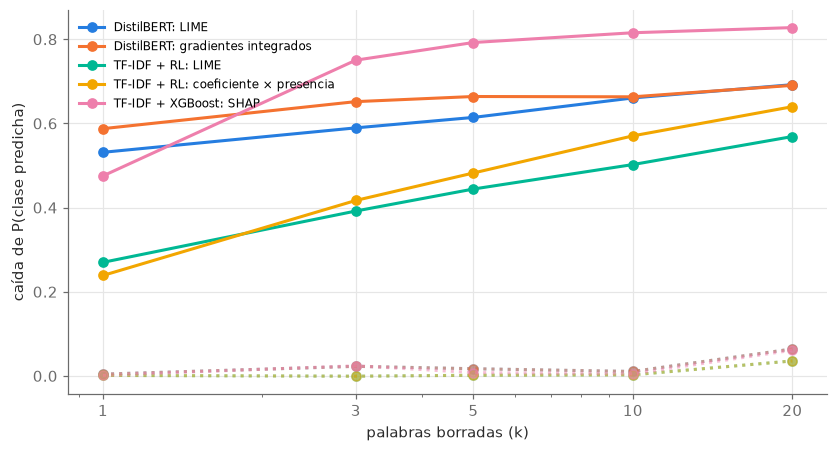

modelo,método,documentos,caída top-5,caída azar-5,Wilcoxon p
DistilBERT,LIME,30,0.614,0.017,0.000
DistilBERT,gradientes integrados,30,0.664,0.017,0.000
TF-IDF + RL,LIME,30,0.444,0.002,0.000
TF-IDF + RL,coeficiente × presencia,30,0.482,0.002,0.000
TF-IDF + XGBoost,SHAP,30,0.792,0.008,0.000


In [14]:
if X is not None:
    fd = X["fidelity"]
    ks = list(X["ks"])
    agg = fd.groupby(["model", "method"])[[f"top_{k}" for k in ks] + [f"rand_{k}" for k in ks]].mean()
    fig, ax = plt.subplots(figsize=(7.5, 4))
    for i, ((m, meth), r_) in enumerate(agg.iterrows()):
        c = CAT[i % len(CAT)]
        ax.plot(ks, [r_[f"top_{k}"] for k in ks], "o-", color=c, label=f"{m}: {meth}")
        ax.plot(ks, [r_[f"rand_{k}"] for k in ks], "o:", color=c, alpha=0.5)
    ax.set(xscale="log", xticks=ks, xticklabels=ks, xlabel="palabras borradas (k)", ylabel="caída de P(clase predicha)")
    ax.legend(fontsize=8)
    plt.show()
    rows = []
    for (m, meth), g in fd.groupby(["model", "method"]):
        d5 = g.top_5 - g.rand_5
        from scipy.stats import wilcoxon
        p = wilcoxon(d5).pvalue if (d5 != 0).any() else 1.0
        rows.append(dict(modelo=m, método=meth, documentos=len(g), **{"caída top-5": g.top_5.mean(), "caída azar-5": g.rand_5.mean(),
                                                                       "Wilcoxon p": p}))
    display(pd.DataFrame(rows).style.hide(axis="index").format(precision=3))

Las líneas continuas son las caídas al borrar las palabras mejor atribuidas y las punteadas, al borrar palabras al azar. La prueba de Wilcoxon compara las dos caídas con k = 5 documento a documento. Borrar palabras saca al texto de la distribución de entrenamiento, así que una parte de la caída se debe al cambio de distribución y no a la importancia de las palabras; la comparación con el azar descuenta ese efecto en promedio.

## Taxonomía de errores

Clasificamos los errores del mejor modelo con reglas explícitas aplicadas en orden: documento corto (< 50 palabras), posible error de etiqueta según *confident learning*, título que nombra la clase predicha, clases afines (el par aparece en ≥ 10 % de la fila de la matriz de confusión), baja confianza (< 0.3) y otro.

In [15]:
E = S["errors"]
display(Markdown(f"{L[E['model']]} comete {E['n_errors']} errores en test (predicción con la probabilidad media de las semillas)."))
display(E["counts"].rename("errores").to_frame().assign(fracción=lambda d: d.errores / d.errores.sum()))
display(E["errors"][["ID", "true", "pred", "conf", "category", "n_words"]].head(12).rename(
    columns={"true": "verdadera", "pred": "predicha", "conf": "confianza", "category": "categoría", "n_words": "palabras"}))
display(Markdown("Identificamos cada currículo por su `ID` y no mostramos fragmentos del texto: la anonimización del corpus es "
                 "incompleta (ficha de datos del capítulo {doc}`02_datos_fichas`) y un fragmento podría contener un nombre propio."))

DistilBERT comete 57 errores en test (predicción con la probabilidad media de las semillas).

,errores,fracción
category,,
clases afines (confusión frecuente),25,0.439
otro,18,0.316
baja confianza (ambiguo),8,0.140
el título nombra la clase predicha,6,0.105


,ID,verdadera,predicha,confianza,categoría,palabras
0,12763627,INFORMATION-TECHNOLOGY,DIGITAL-MEDIA,0.256,baja confianza (ambiguo),931
1,28933005,TEACHER,ARTS,0.720,otro,1085
2,26456474,ADVOCATE,HEALTHCARE,0.435,clases afines (confusión frecuente),717
3,10818478,ADVOCATE,APPAREL,0.713,clases afines (confusión frecuente),311
4,24124250,ADVOCATE,HEALTHCARE,0.843,clases afines (confusión frecuente),704
5,13342150,ADVOCATE,APPAREL,0.236,clases afines (confusión frecuente),731
6,28111403,ADVOCATE,AGRICULTURE,0.176,baja confianza (ambiguo),1152
7,24695561,ADVOCATE,HEALTHCARE,0.822,clases afines (confusión frecuente),1015
8,93512385,ADVOCATE,BANKING,0.840,otro,331
9,75435017,ADVOCATE,HEALTHCARE,0.438,clases afines (confusión frecuente),1061


Identificamos cada currículo por su `ID` y no mostramos fragmentos del texto: la anonimización del corpus es incompleta (ficha de datos del capítulo {doc}`02_datos_fichas`) y un fragmento podría contener un nombre propio.

In [16]:
an = S.get("annotation", {})
if an.get("kappa") is not None:
    display(Markdown(f"Anotación manual: {an['n_annotated']} errores anotados por dos personas, κ de Cohen = {an['kappa']:.2f}."))
else:
    display(Markdown(f"La hoja `reports/anotacion_errores_nlp.csv` contiene 60 errores para anotar a mano con categorías fijadas a priori; "
                     f"hoy tiene {an.get('n_annotated', 0)} anotados por los dos integrantes. El κ de Cohen se calcula cuando hay al menos 20."))

La hoja `reports/anotacion_errores_nlp.csv` contiene 60 errores para anotar a mano con categorías fijadas a priori; hoy tiene 0 anotados por los dos integrantes. El κ de Cohen se calcula cuando hay al menos 20.

Las reglas automáticas son reproducibles pero gruesas: no distinguen un perfil mixto (alguien que fue profesor y luego trabajó en tecnología) de un error de etiqueta. La anotación manual con dos anotadores y κ cubre esa distinción.